# 02 — Análise exploratória avançada do levantamento

Este notebook usa exclusivamente a base preparada por `01_preparacao_dados.ipynb`.

**Entradas**
- `dados_processados.csv`
- `dicionario_dados.csv`


## 1. Importações, caminhos e padrão de exportação

In [1]:
from pathlib import Path
from math import sqrt
import re
import unicodedata
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, dendrogram

import networkx as nx

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

ARQUIVO_DADOS = Path("dados_processados.csv")
ARQUIVO_DICIONARIO = Path("dicionario_dados.csv")

PASTA_FIGURAS = Path("figuras_eda")
PASTA_TABELAS = Path("tabelas_eda")
PASTA_FIGURAS.mkdir(exist_ok=True)
PASTA_TABELAS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 11,
})

def finalizar_figura(nome):
    plt.tight_layout()
    plt.savefig(PASTA_FIGURAS / f"{nome}.png", bbox_inches="tight")
    plt.savefig(PASTA_FIGURAS / f"{nome}.svg", bbox_inches="tight")
    plt.show()

def quebrar_rotulo(texto, largura=32):
    return textwrap.fill(str(texto), width=largura)

## 2. Carregamento e checagem da base

In [2]:
if not ARQUIVO_DADOS.exists():
    raise FileNotFoundError(
        "dados_processados.csv não encontrado. "
        "Execute primeiro o notebook 01_preparacao_dados.ipynb."
    )

dados = pd.read_csv(ARQUIVO_DADOS)

dicionario = (
    pd.read_csv(ARQUIVO_DICIONARIO)
    if ARQUIVO_DICIONARIO.exists()
    else None
)

print("Dimensão:", dados.shape)
print("Respondentes:", len(dados))
print("Colunas:", dados.shape[1])
print("Duplicados exatos:", dados.duplicated().sum())
print("Valores ausentes:", int(dados.isna().sum().sum()))

dados.head()

Dimensão: (13, 103)
Respondentes: 13
Colunas: 103
Duplicados exatos: 0
Valores ausentes: 20


,funcao,nivel,tempo_exp,tipos_ocorrencia,notificacao,desafios,grau_fp,dados_registro,tempo_resp,internet,cadastro,ver_ocorrencias_proximas,telas,filtros_mapa,regra_confirmado,responsavel_validacao,fontes_dados,horizonte_prev,usabilidade,usa_modelo,verificacao,explicacao,funcionalidades,riscos,grau_util,aceite_teste,tempo_exp_ord,tempo_resp_ord,internet_ord,usa_modelo_status,modelo_informado,tipos_ocorrencia__deslizamento,tipos_ocorrencia__ensino_ambiental,tipos_ocorrencia__incendio_queimada,tipos_ocorrencia__inundacao_alagamento,tipos_ocorrencia__queda_de_arvores,tipos_ocorrencia__resgate,tipos_ocorrencia__seca_estiagem,tipos_ocorrencia__tempestade_vento_forte,tipos_ocorrencia__vazamento_de_oleo_no_rio,notificacao__redes_sociais,notificacao__satelite_inpe_queimadas,notificacao__sensores_estacoes,notificacao__sistemas_oficiais,notificacao__telefone_whatsapp,notificacao__vistorias_em_campo,desafios__dados_incompletos,desafios__demora_para_triagem,desafios__dificuldade_de_priorizar_recursos,desafios__falsos_alarmes,desafios__falta_de_geolocalizacao_precisa,desafios__falta_de_padronizacao_classificacao,desafios__pouca_integracao_entre_fontes,dados_registro__categoria,dados_registro__data_hora_automatica,dados_registro__foto,dados_registro__indicar_se_ha_vitimas_risco_humano,dados_registro__localizacao_gps_automatica,dados_registro__nivel_de_urgencia_baixa_media_alta,dados_registro__permitir_ajustar_o_ponto_no_mapa,dados_registro__subcategoria_detalhe,dados_registro__texto_livre,dados_registro__video,dados_registro__audio,telas__exportacao_relatorios,telas__gestao_de_usuarios_logs,telas__lista_de_ocorrencias,telas__mapa_em_tempo_real,telas__painel_analitico_graficos,telas__previsao_7_dias,filtros_mapa__confianca_do_modelo,filtros_mapa__data_periodo,filtros_mapa__fonte_cidadao_satelite_outro,filtros_mapa__municipio_bairro,filtros_mapa__raio_distancia,filtros_mapa__status_confirmado_em_analise,filtros_mapa__tipo_de_desastre,responsavel_validacao__equipe_interna_central,responsavel_validacao__equipes_de_campo,responsavel_validacao__nao_existe_validacao_formal,responsavel_validacao__orgao_parceiro,fontes_dados__chuvas_niveis_de_rio,fontes_dados__dados_inpe_focos_de_calor_etc,fontes_dados__dados_socioambientais_desmatamento_uso_do_solo,fontes_dados__estacoes_meteorologicas,fontes_dados__historico_de_ocorrencias_planilhas_sistema,fontes_dados__satelite_sentinel_landsat_gee,horizonte_prev__15_dias,horizonte_prev__24_48h,horizonte_prev__7_dias,horizonte_prev__sazonal_30_90_dias,usabilidade__alerta_por_regiao_com_nivel_baixo_medio_alto,usabilidade__historico_comparativo,usabilidade__justificativa_variaveis_principais,usabilidade__probabilidade,usabilidade__tendencia_subindo_descendo,verificacao__comparacao_com_eventos_anteriores,verificacao__confianca,verificacao__evidencia_visual_ex_mapa_de_ativacao_grad_cam,verificacao__exemplos_parecidos_casos_historicos,verificacao__nao_preciso_de_explicacao_so_performance,verificacao__texto_explicativo_em_linguagem_simples,verificacao__variaveis_mais_importantes_shap
0,Engenharia Ambiental e Sanitária,Municipal,1 - 3,Tempestade/vento forte;Seca/estiagem,Redes sociais,Falta de padronização/classificação;Falta de geolocalização precisa;Pouca integração entre fontes,4,Foto;Texto livre;Localização GPS automática;Data/hora automática;Nível de urgência (baixa/média/alta);Indicar se há ...,até 5 min,Sim,Obrigatório,"Sim, todas",Mapa em tempo real;Painel analítico (gráficos);Previsão (7 dias),Tipo de desastre;Data/período;Raio/distância,Confiança ≥ 80%,Equipe interna (central),"Dados socioambientais (desmatamento, uso do solo)",24–48h,Justificativa (variáveis principais);Histórico comparativo,Não,Confiança (%);Evidência visual (ex: mapa de ativação/Grad-CAM);Texto explicativo em linguagem simples;Exemplos parec...,Técnica (para analistas),"Segurança, transparência e estudos técnicos","Erro, informações incorretas e nervosismo",5,Sim,1,1,2,Não,NaN,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,1,1,1,0,1,1,1,1,1,0,0,1,0,

## 3. Funções auxiliares



In [3]:
def slug(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    texto = texto.lower()
    texto = re.sub(r"[^a-z0-9]+", "_", texto)
    return texto.strip("_")


def mapa_rotulos_multiplos(df, prefixo):
    if prefixo not in df.columns:
        return {}

    opcoes = (
        df[prefixo]
        .dropna()
        .astype(str)
        .str.split(";")
        .explode()
        .str.strip()
    )

    opcoes = opcoes[opcoes.ne("")]
    return {slug(opcao): opcao for opcao in sorted(opcoes.unique())}


def indicadores(df, prefixo):
    return [c for c in df.columns if c.startswith(prefixo + "__")]


def rotulo_indicador(df, prefixo, coluna):
    sufixo = coluna.split("__", 1)[1]
    mapa = mapa_rotulos_multiplos(df, prefixo)
    return mapa.get(sufixo, sufixo.replace("_", " ").title())


def frequencia_simples(df, coluna):
    contagem = df[coluna].value_counts(dropna=False)
    resultado = pd.DataFrame({
        "frequencia": contagem,
        "percentual_total": (contagem / len(df) * 100).round(1),
    })
    return resultado


def frequencia_multipla(df, prefixo):
    cols = indicadores(df, prefixo)
    if not cols:
        raise ValueError(f"Indicadores não encontrados para: {prefixo}")

    contagem = df[cols].sum().sort_values(ascending=False)
    resultado = pd.DataFrame({
        "opcao": [rotulo_indicador(df, prefixo, c) for c in contagem.index],
        "frequencia": contagem.astype(int).values,
    })
    resultado["percentual_respondentes"] = (
        resultado["frequencia"] / len(df) * 100
    ).round(1)

    return resultado.set_index("opcao")


def grafico_barras(tabela, titulo, coluna="frequencia", nome=None):
    tabela_plot = tabela.sort_values(coluna)

    fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(tabela_plot))))
    barras = ax.barh(
        [quebrar_rotulo(x) for x in tabela_plot.index],
        tabela_plot[coluna]
    )

    ax.set_title(titulo)
    ax.set_xlabel("Número de respondentes")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.2)

    for barra, valor in zip(barras, tabela_plot[coluna]):
        ax.text(
            barra.get_width() + 0.08,
            barra.get_y() + barra.get_height()/2,
            str(int(valor)),
            va="center"
        )

    if nome:
        finalizar_figura(nome)
    else:
        plt.tight_layout()
        plt.show()

# Parte A — Descrição básica

Esta parte preserva a análise tradicional: quem respondeu, quais problemas aparecem e quais requisitos foram mais selecionados. Ela serve como base para as análises multivariadas posteriores.

## 4. Perfil dos participantes

,frequencia,percentual_total
funcao,,
Pesquisa/academia,3,23.1
Gestão pública,2,15.4
Defesa Civil/Operações,2,15.4
Bombeiro(a) Militar,2,15.4
ONG / brigadista / monitoramento,1,7.7
Engenharia Ambiental e Sanitária,1,7.7
Resposta não classificável,1,7.7
Engenheiro florestal,1,7.7


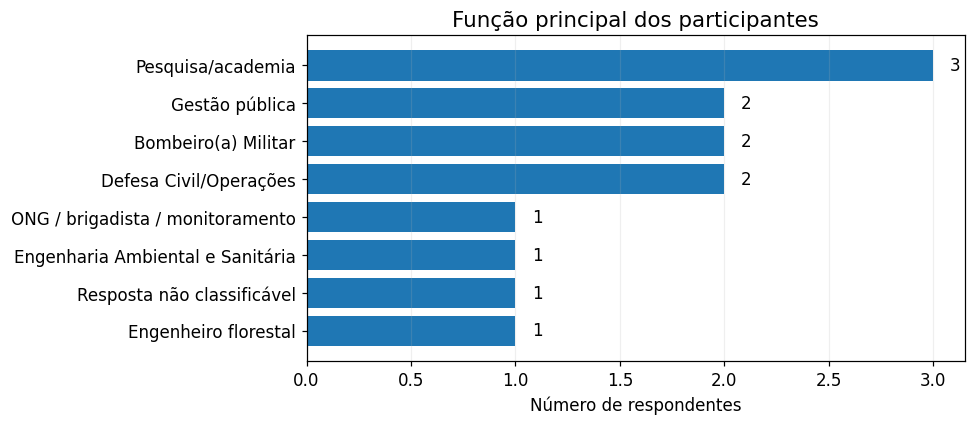

,frequencia,percentual_total
nivel,,
Municipal,6,46.2
Estadual,4,30.8
Federal,3,23.1


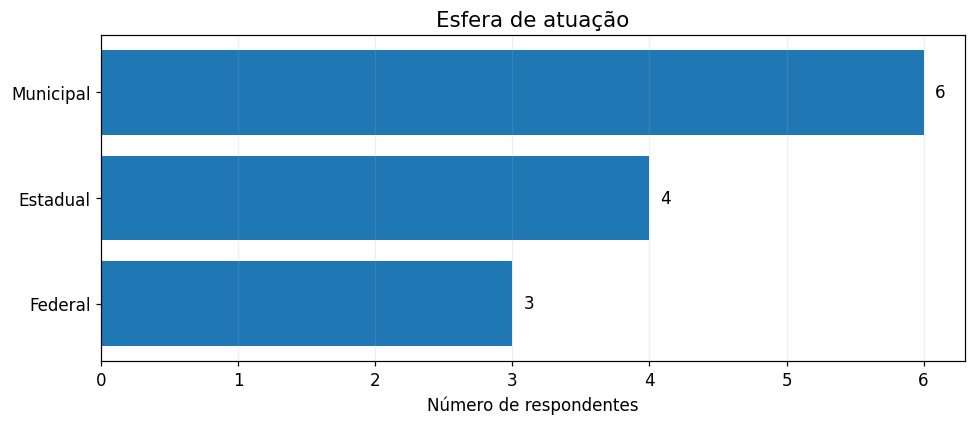

,frequencia,percentual_total
tempo_exp,,
8+,5,38.5
1 - 3,3,23.1
< 1 ano,3,23.1
4 - 7,2,15.4


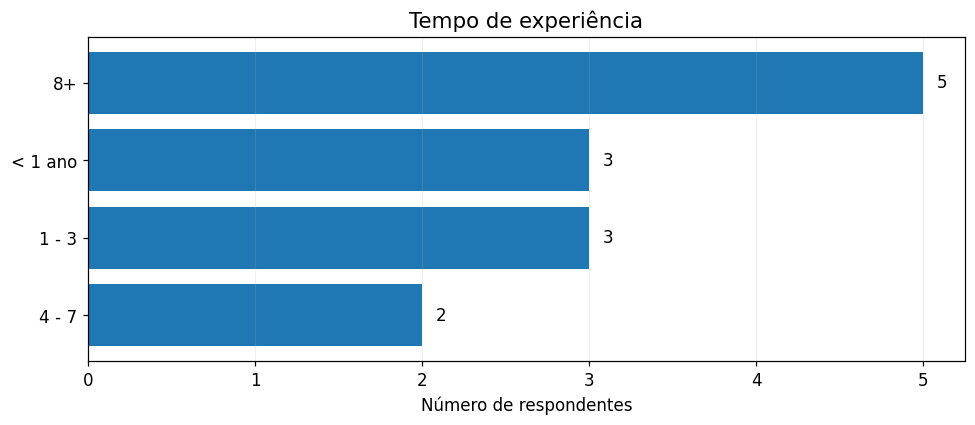

In [4]:
for coluna, titulo in [
    ("funcao", "Função principal dos participantes"),
    ("nivel", "Esfera de atuação"),
    ("tempo_exp", "Tempo de experiência"),
]:
    tabela = frequencia_simples(dados, coluna)
    display(tabela)
    grafico_barras(
        tabela,
        titulo=titulo,
        nome=f"perfil_{coluna}"
    )

## 5. Processo atual e principais dificuldades

,frequencia,percentual_respondentes
opcao,,
Seca/estiagem,6,46.2
Incêndio/queimada,5,38.5
Tempestade/vento forte,3,23.1
Inundação/alagamento,3,23.1
Deslizamento,2,15.4
Queda de árvores,1,7.7
Ensino ambiental,1,7.7
Resgate,1,7.7
Vazamento de óleo no rio,1,7.7


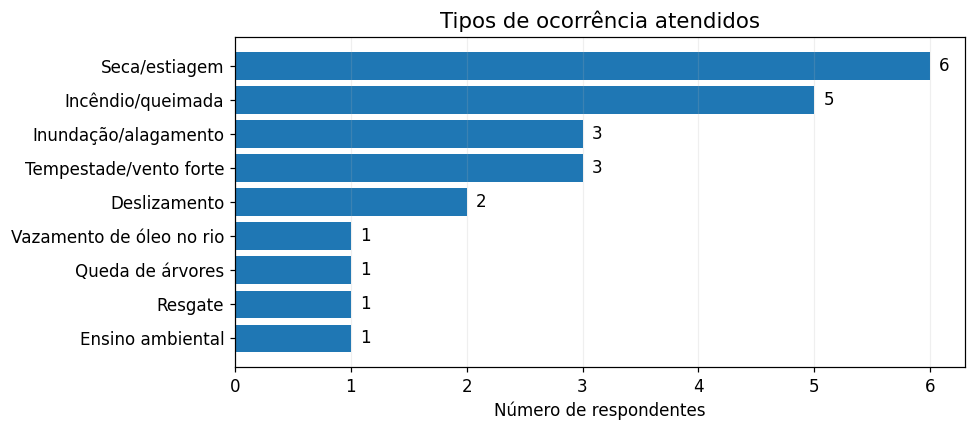

,frequencia,percentual_respondentes
opcao,,
Telefone/WhatsApp,9,69.2
Redes sociais,8,61.5
Sistemas oficiais,3,23.1
Satélite/INPE/queimadas,2,15.4
Vistorias em campo,2,15.4
Sensores/estações,1,7.7


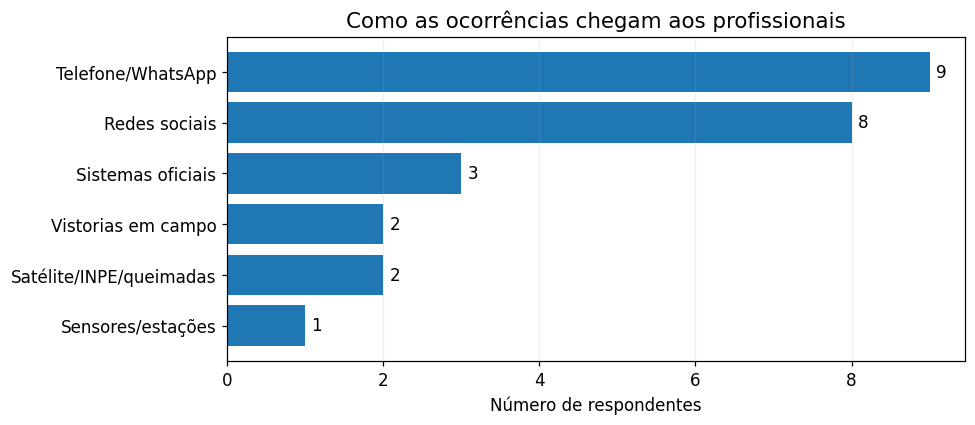

,frequencia,percentual_respondentes
opcao,,
Dados incompletos,5,38.5
Dificuldade de priorizar recursos,4,30.8
Falta de geolocalização precisa,4,30.8
Pouca integração entre fontes,4,30.8
Falta de padronização/classificação,4,30.8
Demora para triagem,3,23.1
Falsos alarmes,1,7.7


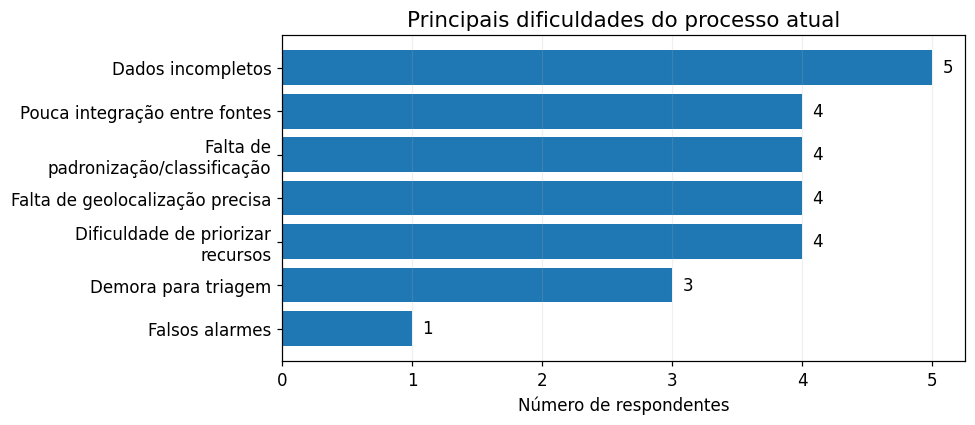

In [5]:
for prefixo, titulo in [
    ("tipos_ocorrencia", "Tipos de ocorrência atendidos"),
    ("notificacao", "Como as ocorrências chegam aos profissionais"),
    ("desafios", "Principais dificuldades do processo atual"),
]:
    tabela = frequencia_multipla(dados, prefixo)
    display(tabela)
    tabela.to_csv(
        PASTA_TABELAS / f"{prefixo}_frequencias.csv",
        encoding="utf-8-sig"
    )
    grafico_barras(
        tabela,
        titulo=titulo,
        nome=f"basico_{prefixo}"
    )

## 6. Requisitos prioritários do sistema

,frequencia,percentual_respondentes
opcao,,
Foto,12,92.3
Localização GPS automática,11,84.6
Nível de urgência (baixa/média/alta),9,69.2
Vídeo,9,69.2
Indicar se há vítimas/risco humano,8,61.5
Data/hora automática,6,46.2
Texto livre,3,23.1
Categoria,2,15.4
Áudio,2,15.4


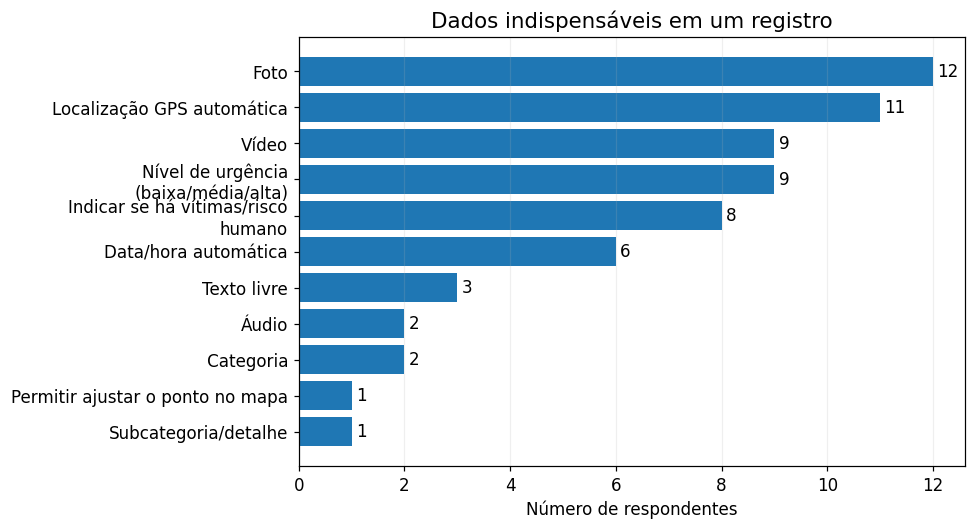

,frequencia,percentual_respondentes
opcao,,
Mapa em tempo real,12,92.3
Painel analítico (gráficos),10,76.9
Lista de ocorrências,8,61.5
Previsão (7 dias),7,53.8
Gestão de usuários/logs,5,38.5
Exportação/relatórios,4,30.8


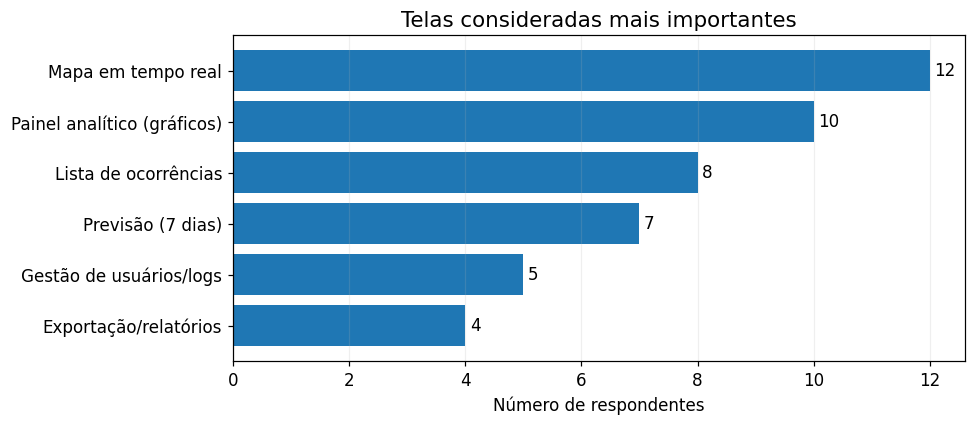

,frequencia,percentual_respondentes
opcao,,
Tipo de desastre,11,84.6
Data/período,9,69.2
Raio/distância,7,53.8
Status (confirmado/em análise),4,30.8
Confiança do modelo,4,30.8
Município/bairro,3,23.1
Fonte (cidadão/satélite/outro),1,7.7


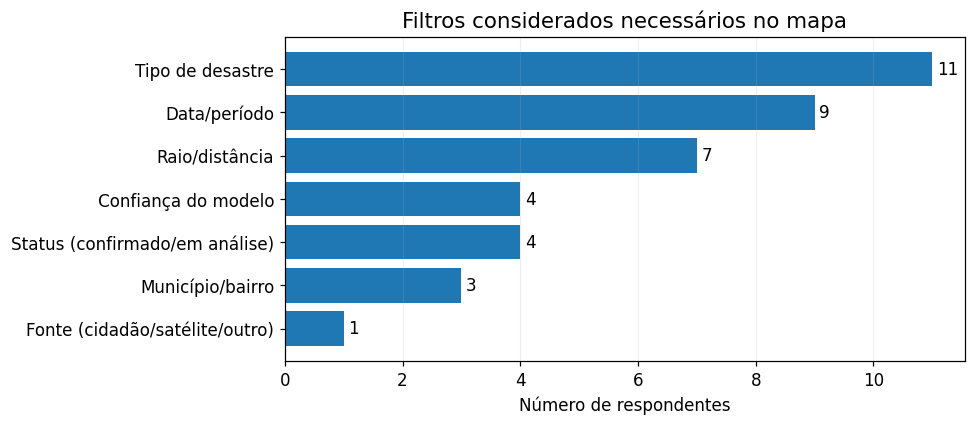

,frequencia,percentual_respondentes
opcao,,
Confiança (%),10,76.9
Evidência visual (ex: mapa de ativação/Grad-CAM),10,76.9
Variáveis mais importantes (SHAP),5,38.5
Comparação com eventos anteriores,4,30.8
Texto explicativo em linguagem simples,4,30.8
Exemplos parecidos (casos históricos),3,23.1
"Não preciso de explicação, só performance",1,7.7


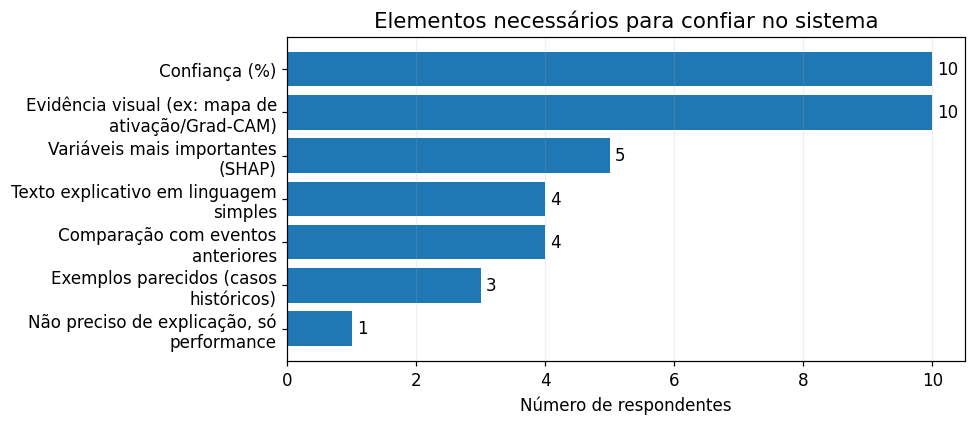

In [6]:
for prefixo, titulo in [
    ("dados_registro", "Dados indispensáveis em um registro"),
    ("telas", "Telas consideradas mais importantes"),
    ("filtros_mapa", "Filtros considerados necessários no mapa"),
    ("verificacao", "Elementos necessários para confiar no sistema"),
]:
    tabela = frequencia_multipla(dados, prefixo)
    display(tabela)
    tabela.to_csv(
        PASTA_TABELAS / f"{prefixo}_frequencias.csv",
        encoding="utf-8-sig"
    )
    grafico_barras(
        tabela,
        titulo=titulo,
        nome=f"requisitos_{prefixo}"
    )

# Parte B — Proporções e incerteza

Com apenas 13 participantes, apresentar somente algo como “92,3% escolheram mapa” pode transmitir precisão excessiva. Por isso, além da proporção observada, esta seção mostra um **intervalo de Wilson de 95%**.

O intervalo não torna a amostra representativa; ele apenas deixa visualmente explícita a incerteza associada ao tamanho amostral.

## 7. Forest plot de prioridades com intervalo de Wilson

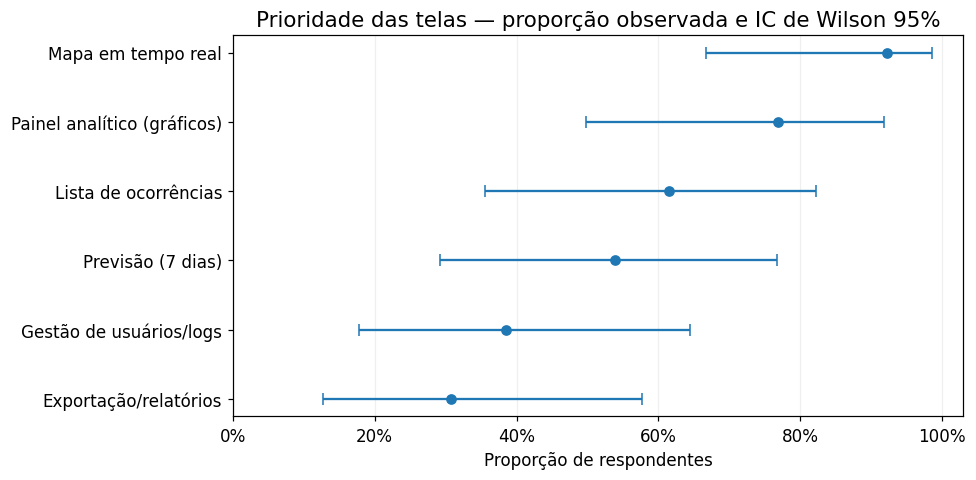

,frequencia,percentual_respondentes,proporcao,ic95_inf,ic95_sup
opcao,,,,,
Exportação/relatórios,4,30.8,0.307692,0.126805,0.576311
Gestão de usuários/logs,5,38.5,0.384615,0.177094,0.644775
Previsão (7 dias),7,53.8,0.538462,0.291434,0.767942
Lista de ocorrências,8,61.5,0.615385,0.355225,0.822906
Painel analítico (gráficos),10,76.9,0.769231,0.497431,0.918206
Mapa em tempo real,12,92.3,0.923077,0.666855,0.986290


In [7]:
def intervalo_wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan

    p = k / n
    den = 1 + (z**2 / n)
    centro = (p + z**2 / (2*n)) / den
    margem = (
        z
        * sqrt((p*(1-p)/n) + (z**2/(4*n**2)))
        / den
    )
    return centro - margem, centro + margem


def tabela_wilson_multipla(df, prefixo):
    tabela = frequencia_multipla(df, prefixo).copy()
    n = len(df)

    limites = [
        intervalo_wilson(int(k), n)
        for k in tabela["frequencia"]
    ]

    tabela["proporcao"] = tabela["frequencia"] / n
    tabela["ic95_inf"] = [a for a, _ in limites]
    tabela["ic95_sup"] = [b for _, b in limites]

    return tabela


def forest_plot_multipla(df, prefixo, titulo, nome):
    tabela = tabela_wilson_multipla(df, prefixo).sort_values("proporcao")

    y = np.arange(len(tabela))
    p = tabela["proporcao"].to_numpy()
    inf = tabela["ic95_inf"].to_numpy()
    sup = tabela["ic95_sup"].to_numpy()

    fig, ax = plt.subplots(figsize=(9, max(4.5, 0.52 * len(tabela))))

    ax.errorbar(
        p,
        y,
        xerr=np.vstack([p-inf, sup-p]),
        fmt="o",
        capsize=4
    )

    ax.set_yticks(y)
    ax.set_yticklabels([quebrar_rotulo(x) for x in tabela.index])
    ax.set_xlim(0, 1.03)
    ax.set_xlabel("Proporção de respondentes")
    ax.set_title(titulo)
    ax.grid(axis="x", alpha=0.2)

    ticks = np.linspace(0, 1, 6)
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{v:.0%}" for v in ticks])

    finalizar_figura(nome)
    return tabela


tabela_ic_telas = forest_plot_multipla(
    dados,
    "telas",
    "Prioridade das telas — proporção observada e IC de Wilson 95%",
    "forest_telas_ic95"
)

display(tabela_ic_telas)

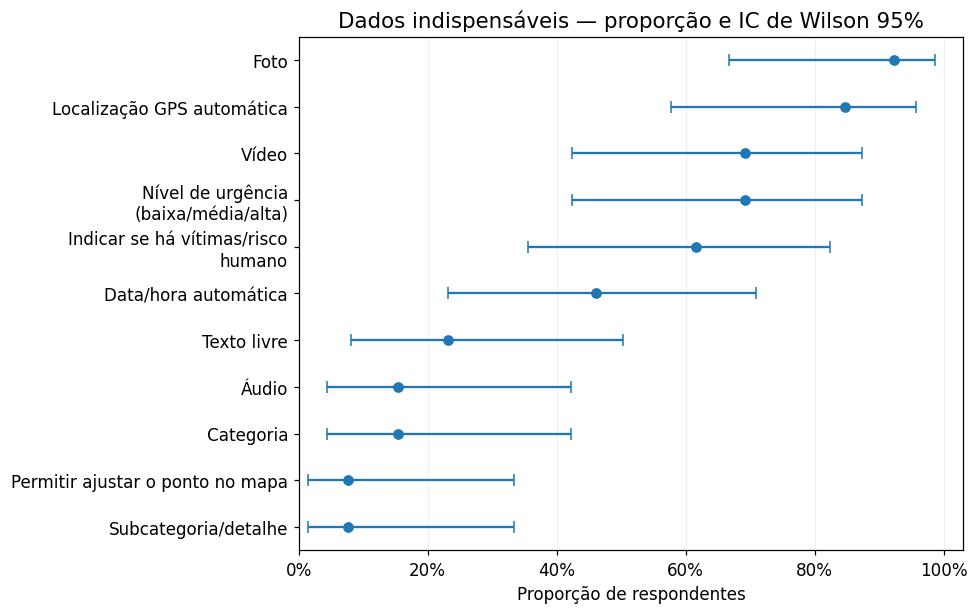

,frequencia,percentual_respondentes,proporcao,ic95_inf,ic95_sup
opcao,,,,,
Subcategoria/detalhe,1,7.7,0.076923,0.013710,0.333145
Permitir ajustar o ponto no mapa,1,7.7,0.076923,0.013710,0.333145
Categoria,2,15.4,0.153846,0.043257,0.422352
Áudio,2,15.4,0.153846,0.043257,0.422352
Texto livre,3,23.1,0.230769,0.081794,0.502569
Data/hora automática,6,46.2,0.461538,0.232058,0.708566
Indicar se há vítimas/risco humano,8,61.5,0.615385,0.355225,0.822906
Nível de urgência (baixa/média/alta),9,69.2,0.692308,0.423689,0.873195
Vídeo,9,69.2,0.692308,0.423689,0.873195


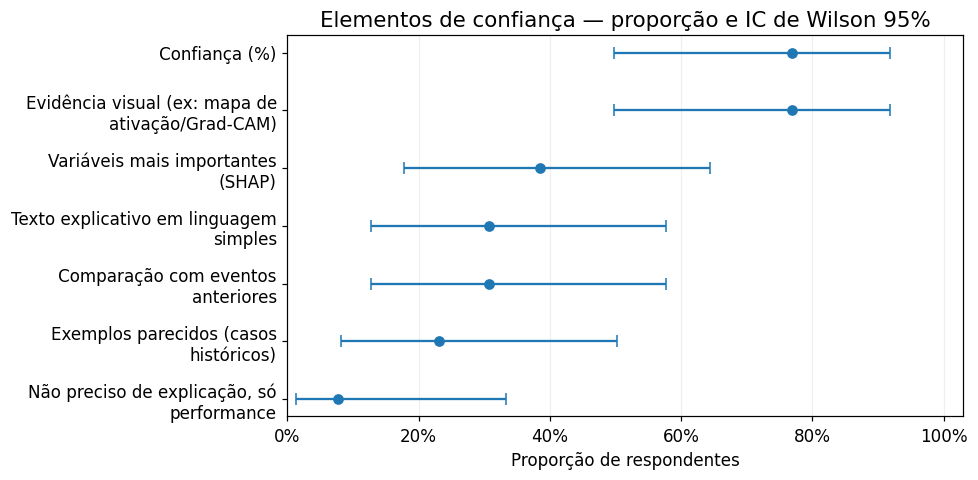

,frequencia,percentual_respondentes,proporcao,ic95_inf,ic95_sup
opcao,,,,,
"Não preciso de explicação, só performance",1,7.7,0.076923,0.013710,0.333145
Exemplos parecidos (casos históricos),3,23.1,0.230769,0.081794,0.502569
Comparação com eventos anteriores,4,30.8,0.307692,0.126805,0.576311
Texto explicativo em linguagem simples,4,30.8,0.307692,0.126805,0.576311
Variáveis mais importantes (SHAP),5,38.5,0.384615,0.177094,0.644775
Evidência visual (ex: mapa de ativação/Grad-CAM),10,76.9,0.769231,0.497431,0.918206
Confiança (%),10,76.9,0.769231,0.497431,0.918206


In [8]:
for prefixo, titulo, nome in [
    (
        "dados_registro",
        "Dados indispensáveis — proporção e IC de Wilson 95%",
        "forest_dados_registro_ic95"
    ),
    (
        "verificacao",
        "Elementos de confiança — proporção e IC de Wilson 95%",
        "forest_verificacao_ic95"
    ),
]:
    tabela = forest_plot_multipla(dados, prefixo, titulo, nome)
    display(tabela)

# Parte C — Escalas ordinais

`grau_fp` e `grau_util` são itens Likert 1–5. Em vez de tratá-los como medidas contínuas, priorizamos distribuição, mediana, moda e relações ordinais.

## 8. Likert combinado: falsos positivos × utilidade percebida

,1,2,3,4,5
Gravidade dos falsos positivos,23.1,15.4,15.4,23.1,23.1
Utilidade percebida do sistema,7.7,7.7,15.4,23.1,46.2


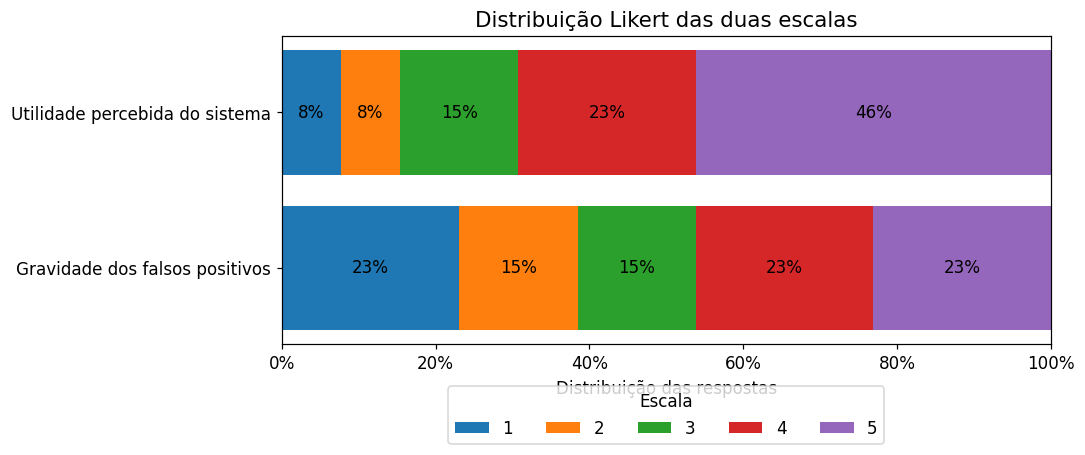

In [9]:
likert = pd.DataFrame({
    "Gravidade dos falsos positivos": (
        dados["grau_fp"]
        .value_counts(normalize=True)
        .reindex([1, 2, 3, 4, 5], fill_value=0)
    ),
    "Utilidade percebida do sistema": (
        dados["grau_util"]
        .value_counts(normalize=True)
        .reindex([1, 2, 3, 4, 5], fill_value=0)
    ),
}).T

display((likert * 100).round(1))

fig, ax = plt.subplots(figsize=(10, 4.5))

esquerda = np.zeros(len(likert))

for categoria in [1, 2, 3, 4, 5]:
    valores = likert[categoria].to_numpy()
    ax.barh(
        likert.index,
        valores,
        left=esquerda,
        label=str(categoria)
    )

    for i, (inicio, valor) in enumerate(zip(esquerda, valores)):
        if valor >= 0.07:
            ax.text(
                inicio + valor/2,
                i,
                f"{valor:.0%}",
                ha="center",
                va="center"
            )

    esquerda += valores

ax.set_xlim(0, 1)
ax.set_xlabel("Distribuição das respostas")
ax.set_title("Distribuição Likert das duas escalas")
ax.legend(
    title="Escala",
    ncol=5,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.35)
)

ticks = np.linspace(0, 1, 6)
ax.set_xticks(ticks)
ax.set_xticklabels([f"{x:.0%}" for x in ticks])

finalizar_figura("likert_combinado")

## 9. Matriz de bolhas: gravidade dos falsos positivos × utilidade

grau_util,1,2,3,4,5
grau_fp,,,,,
1,1,1,0,1,0
2,0,0,1,0,1
3,0,0,1,0,1
4,0,0,0,2,1
5,0,0,0,0,3


Spearman exploratório: rho = 0.686; p = 0.010
Interprete o coeficiente como tendência na amostra, não como evidência populacional.


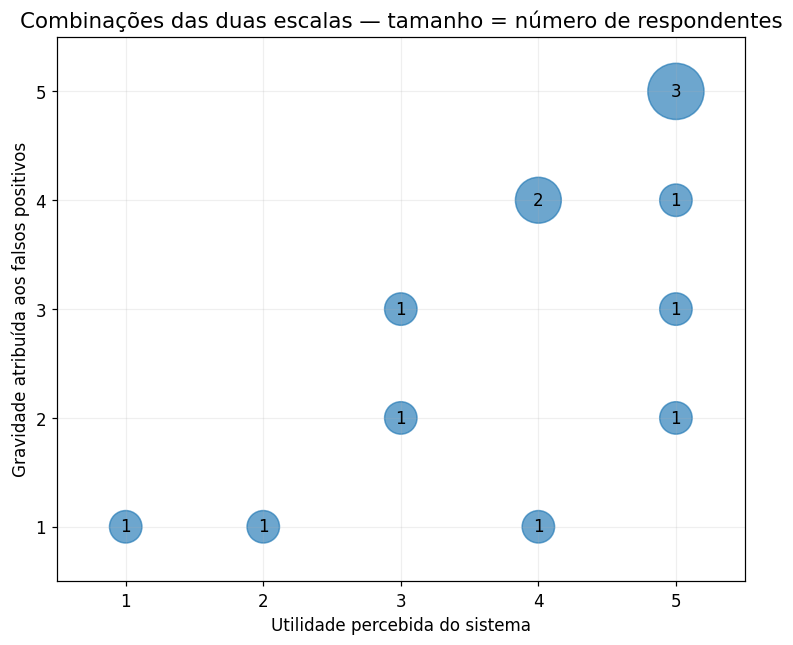

In [10]:
matriz_bolhas = pd.crosstab(
    dados["grau_fp"],
    dados["grau_util"]
).reindex(
    index=[1, 2, 3, 4, 5],
    columns=[1, 2, 3, 4, 5],
    fill_value=0
)

display(matriz_bolhas)

x = []
y = []
tamanhos = []
contagens = []

for fp in matriz_bolhas.index:
    for util in matriz_bolhas.columns:
        n = int(matriz_bolhas.loc[fp, util])
        if n > 0:
            x.append(util)
            y.append(fp)
            tamanhos.append(n * 450)
            contagens.append(n)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(x, y, s=tamanhos, alpha=0.65)

for xi, yi, n in zip(x, y, contagens):
    ax.text(xi, yi, str(n), ha="center", va="center")

ax.set_xticks([1, 2, 3, 4, 5])
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_xlim(0.5, 5.5)
ax.set_ylim(0.5, 5.5)
ax.set_xlabel("Utilidade percebida do sistema")
ax.set_ylabel("Gravidade atribuída aos falsos positivos")
ax.set_title("Combinações das duas escalas — tamanho = número de respondentes")
ax.grid(alpha=0.2)

rho, p = spearmanr(
    dados["grau_fp"],
    dados["grau_util"],
    nan_policy="omit"
)

print(f"Spearman exploratório: rho = {rho:.3f}; p = {p:.3f}")
print(
    "Interprete o coeficiente como tendência na amostra, "
    "não como evidência populacional."
)

finalizar_figura("bolhas_grau_fp_vs_utilidade")

## 10. Matriz de associação de Spearman entre variáveis ordinais

,tempo_exp_ord,tempo_resp_ord,internet_ord,grau_fp,grau_util
tempo_exp_ord,1.00,-0.09,0.40,-0.33,-0.46
tempo_resp_ord,-0.09,1.00,0.31,-0.06,-0.24
internet_ord,0.40,0.31,1.00,0.04,-0.29
grau_fp,-0.33,-0.06,0.04,1.00,0.69
grau_util,-0.46,-0.24,-0.29,0.69,1.00


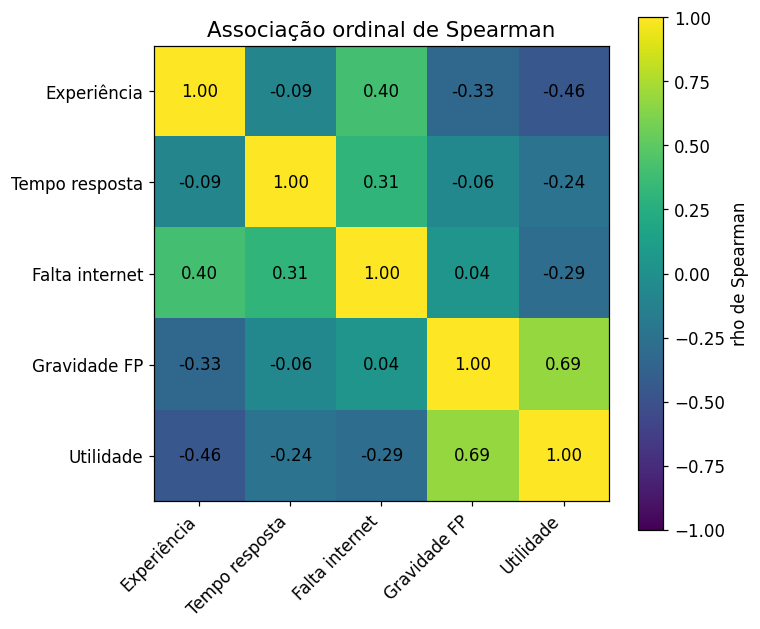

In [11]:
ordinais = [
    "tempo_exp_ord",
    "tempo_resp_ord",
    "internet_ord",
    "grau_fp",
    "grau_util",
]

rotulos_ordinais = {
    "tempo_exp_ord": "Experiência",
    "tempo_resp_ord": "Tempo resposta",
    "internet_ord": "Falta internet",
    "grau_fp": "Gravidade FP",
    "grau_util": "Utilidade",
}

corr = dados[ordinais].corr(method="spearman")
display(corr.round(2))

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.to_numpy(), vmin=-1, vmax=1)

labels = [rotulos_ordinais[c] for c in corr.columns]
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_title("Associação ordinal de Spearman")
plt.colorbar(im, ax=ax, label="rho de Spearman")

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")

finalizar_figura("matriz_spearman_ordinais")

# Parte D — Coocorrência e combinações

As perguntas de múltipla escolha têm uma riqueza que o gráfico de frequência isolado não mostra: **quais opções tendem a aparecer juntas**.

## 11. Matriz de coocorrência

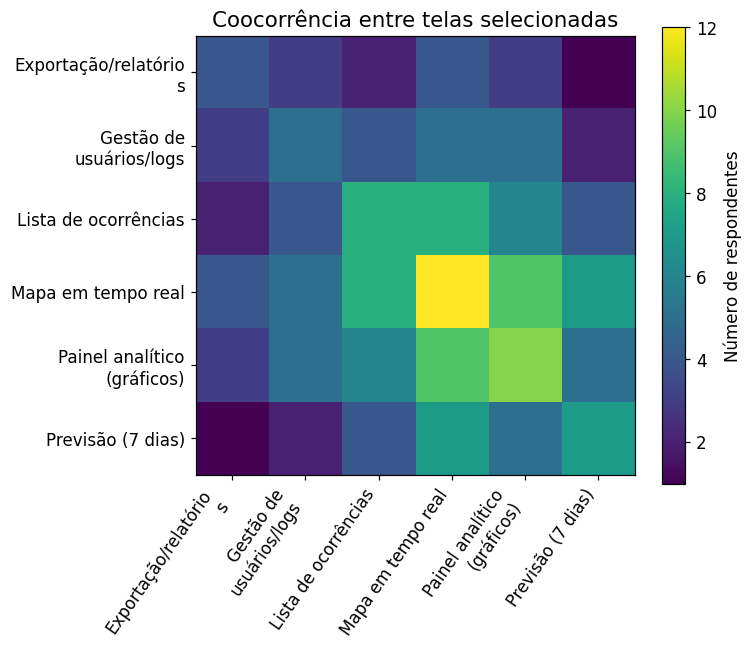

,Exportação/relatórios,Gestão de usuários/logs,Lista de ocorrências,Mapa em tempo real,Painel analítico (gráficos),Previsão (7 dias)
Exportação/relatórios,4,3,2,4,3,1
Gestão de usuários/logs,3,5,4,5,5,2
Lista de ocorrências,2,4,8,8,6,4
Mapa em tempo real,4,5,8,12,9,7
Painel analítico (gráficos),3,5,6,9,10,5
Previsão (7 dias),1,2,4,7,5,7


In [12]:
def matriz_coocorrencia(df, prefixo):
    cols = indicadores(df, prefixo)
    X = df[cols].fillna(0).astype(int)
    cooc = X.T @ X

    rotulos = [rotulo_indicador(df, prefixo, c) for c in cols]
    cooc.index = rotulos
    cooc.columns = rotulos

    return cooc


def plot_coocorrencia(df, prefixo, titulo, nome):
    cooc = matriz_coocorrencia(df, prefixo)

    fig, ax = plt.subplots(
        figsize=(
            max(7, 0.75 * len(cooc)),
            max(6, 0.65 * len(cooc))
        )
    )

    im = ax.imshow(cooc.to_numpy())
    labels = [quebrar_rotulo(x, 20) for x in cooc.index]

    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=55, ha="right")
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax, label="Número de respondentes")

    finalizar_figura(nome)
    return cooc


cooc_telas = plot_coocorrencia(
    dados,
    "telas",
    "Coocorrência entre telas selecionadas",
    "coocorrencia_telas"
)

display(cooc_telas)

## 12. Similaridade de Jaccard entre requisitos

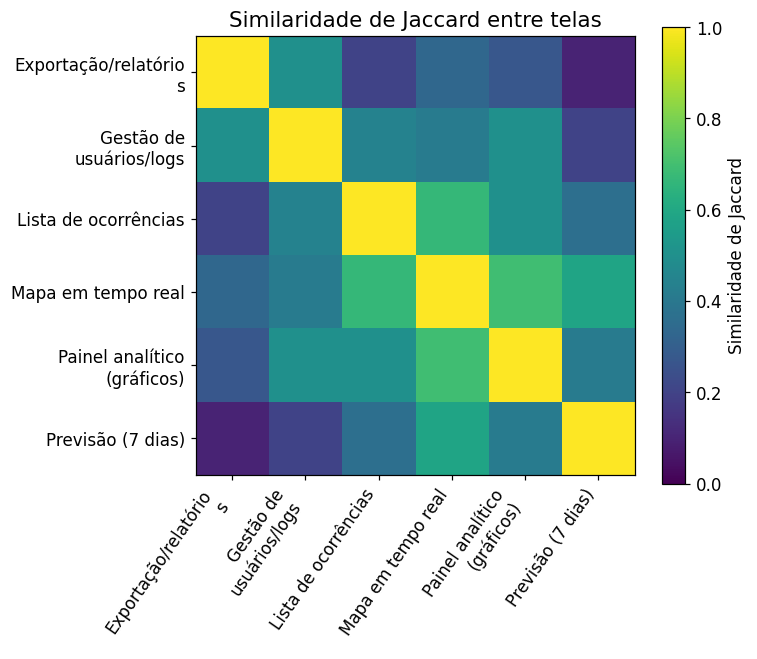

,Exportação/relatórios,Gestão de usuários/logs,Lista de ocorrências,Mapa em tempo real,Painel analítico (gráficos),Previsão (7 dias)
Exportação/relatórios,1.00,0.50,0.20,0.33,0.27,0.10
Gestão de usuários/logs,0.50,1.00,0.44,0.42,0.50,0.20
Lista de ocorrências,0.20,0.44,1.00,0.67,0.50,0.36
Mapa em tempo real,0.33,0.42,0.67,1.00,0.69,0.58
Painel analítico (gráficos),0.27,0.50,0.50,0.69,1.00,0.42
Previsão (7 dias),0.10,0.20,0.36,0.58,0.42,1.00


In [13]:
def matriz_jaccard_opcoes(df, prefixo):
    cols = indicadores(df, prefixo)
    X = df[cols].fillna(0).astype(bool)

    n = len(cols)
    resultado = np.zeros((n, n), dtype=float)

    for i in range(n):
        a = X.iloc[:, i].to_numpy()
        for j in range(n):
            b = X.iloc[:, j].to_numpy()

            uniao = np.logical_or(a, b).sum()
            inter = np.logical_and(a, b).sum()

            resultado[i, j] = inter / uniao if uniao else np.nan

    rotulos = [
        rotulo_indicador(df, prefixo, c)
        for c in cols
    ]

    return pd.DataFrame(
        resultado,
        index=rotulos,
        columns=rotulos
    )


def plot_jaccard(df, prefixo, titulo, nome):
    jac = matriz_jaccard_opcoes(df, prefixo)

    fig, ax = plt.subplots(
        figsize=(
            max(7, 0.75 * len(jac)),
            max(6, 0.65 * len(jac))
        )
    )

    im = ax.imshow(jac.to_numpy(), vmin=0, vmax=1)
    labels = [quebrar_rotulo(x, 20) for x in jac.index]

    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=55, ha="right")
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.set_title(titulo)
    plt.colorbar(im, ax=ax, label="Similaridade de Jaccard")

    finalizar_figura(nome)
    return jac


jaccard_telas = plot_jaccard(
    dados,
    "telas",
    "Similaridade de Jaccard entre telas",
    "jaccard_telas"
)

display(jaccard_telas.round(2))

A coocorrência responde “quantas pessoas escolheram A e B?”.  
Jaccard responde “o quanto os grupos que escolheram A e B se sobrepõem?”, descontando o tamanho de cada grupo.

## 13. Combinações mais frequentes — alternativa simples ao UpSet

,combinacao,frequencia
0,Mapa em tempo real + Painel analítico (gráficos) + Previsão (7 dias),2
1,Gestão de usuários/logs + Lista de ocorrências + Mapa em tempo real + Painel analítico (gráficos) + Previsão (7 dias),2
2,Exportação/relatórios + Gestão de usuários/logs + Lista de ocorrências + Mapa em tempo real + Painel analítico (gráf...,2
3,Lista de ocorrências + Mapa em tempo real + Previsão (7 dias),1
4,Lista de ocorrências + Mapa em tempo real + Painel analítico (gráficos),1
5,Lista de ocorrências + Mapa em tempo real,1
6,Lista de ocorrências + Mapa em tempo real + Painel analítico (gráficos) + Previsão (7 dias),1
7,Exportação/relatórios + Mapa em tempo real + Previsão (7 dias),1
8,Exportação/relatórios + Gestão de usuários/logs + Mapa em tempo real + Painel analítico (gráficos),1
9,Painel analítico (gráficos),1


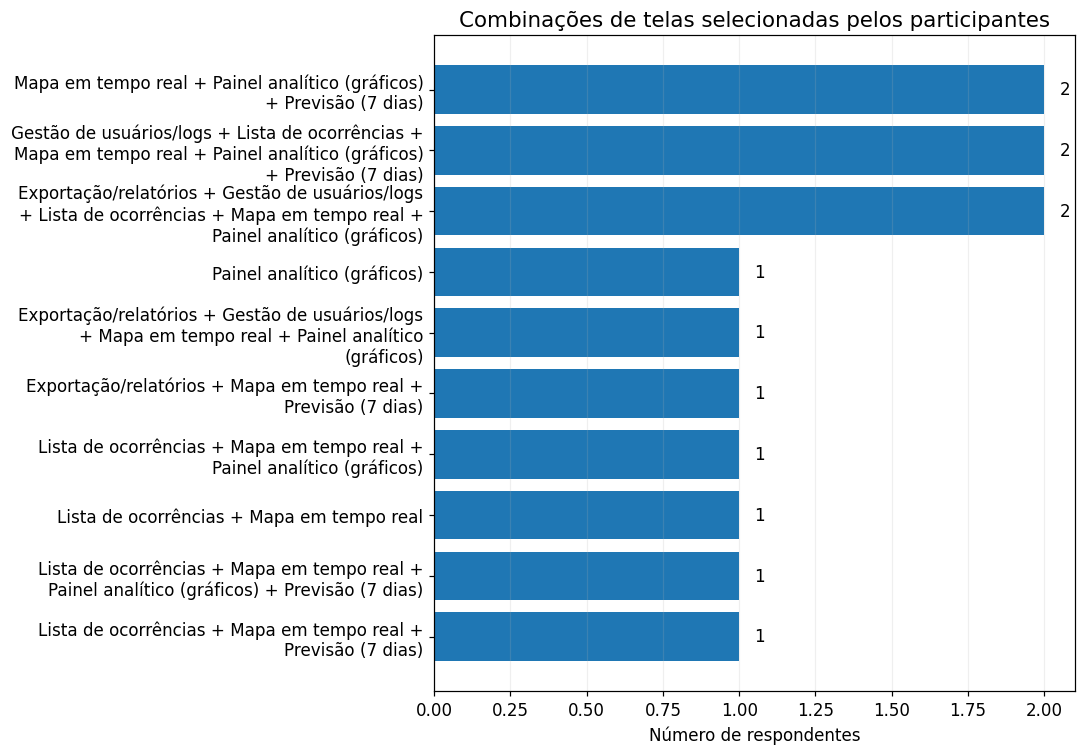

In [14]:
def combinacoes_multiplas(df, coluna, top=10):
    combinacoes = (
        df[coluna]
        .dropna()
        .astype(str)
        .apply(
            lambda x: tuple(
                sorted(
                    item.strip()
                    for item in x.split(";")
                    if item.strip()
                )
            )
        )
        .value_counts()
        .head(top)
    )

    tabela = pd.DataFrame({
        "combinacao": [
            " + ".join(comb)
            for comb in combinacoes.index
        ],
        "frequencia": combinacoes.values,
    })

    return tabela


combinacoes_telas = combinacoes_multiplas(
    dados,
    "telas",
    top=10
)

display(combinacoes_telas)

tabela_plot = combinacoes_telas.sort_values("frequencia")

fig, ax = plt.subplots(figsize=(10, max(5, 0.7 * len(tabela_plot))))
barras = ax.barh(
    [quebrar_rotulo(x, 48) for x in tabela_plot["combinacao"]],
    tabela_plot["frequencia"]
)

ax.set_xlabel("Número de respondentes")
ax.set_title("Combinações de telas selecionadas pelos participantes")
ax.grid(axis="x", alpha=0.2)

for barra, valor in zip(barras, tabela_plot["frequencia"]):
    ax.text(
        barra.get_width() + 0.05,
        barra.get_y() + barra.get_height()/2,
        str(int(valor)),
        va="center"
    )

finalizar_figura("combinacoes_telas")

## 14. Matriz respondente × requisito

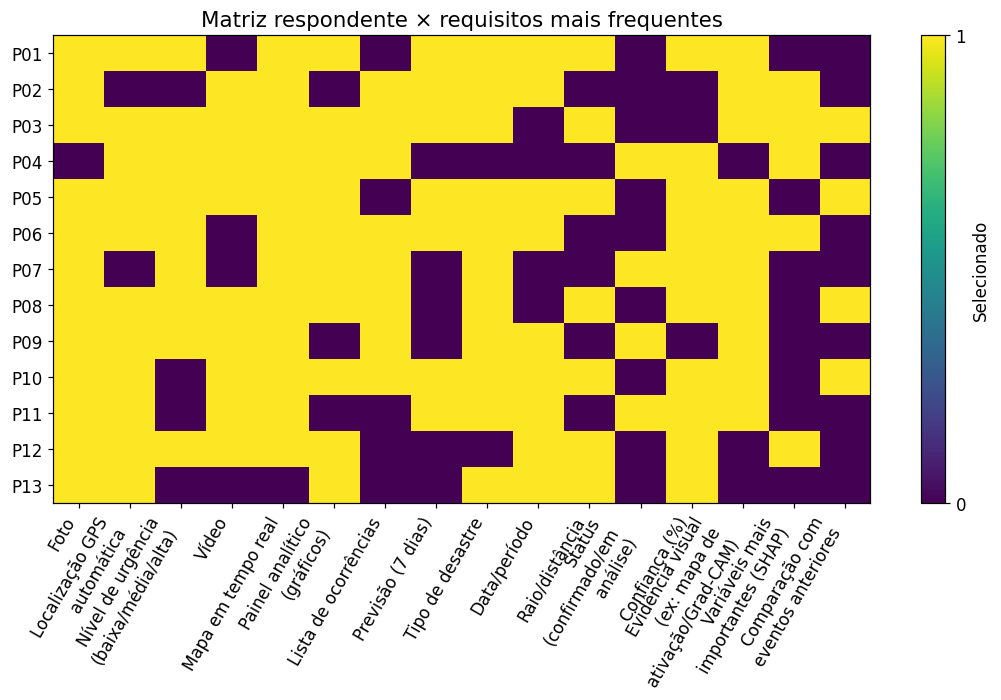

In [15]:
def top_indicadores(df, prefixos, top_por_bloco=5):
    selecionadas = []

    for prefixo in prefixos:
        cols = indicadores(df, prefixo)
        if not cols:
            continue

        soma = (
            df[cols]
            .fillna(0)
            .sum()
            .sort_values(ascending=False)
            .head(top_por_bloco)
        )

        selecionadas.extend(soma.index.tolist())

    # preserva a ordem e remove duplicações
    return list(dict.fromkeys(selecionadas))


prefixos_matriz = [
    "dados_registro",
    "telas",
    "filtros_mapa",
    "verificacao",
]

cols_heatmap = top_indicadores(
    dados,
    prefixos_matriz,
    top_por_bloco=4
)

X = dados[cols_heatmap].fillna(0).astype(int)

labels_colunas = []
for coluna in cols_heatmap:
    prefixo = coluna.split("__", 1)[0]
    labels_colunas.append(
        quebrar_rotulo(
            rotulo_indicador(dados, prefixo, coluna),
            20
        )
    )

labels_linhas = [f"P{i+1:02d}" for i in range(len(dados))]

fig, ax = plt.subplots(
    figsize=(max(10, len(cols_heatmap)*0.62), 6.5)
)

im = ax.imshow(X.to_numpy(), aspect="auto", vmin=0, vmax=1)

ax.set_xticks(range(len(labels_colunas)))
ax.set_xticklabels(labels_colunas, rotation=60, ha="right")
ax.set_yticks(range(len(labels_linhas)))
ax.set_yticklabels(labels_linhas)
ax.set_title("Matriz respondente × requisitos mais frequentes")
plt.colorbar(im, ax=ax, ticks=[0, 1], label="Selecionado")

finalizar_figura("matriz_respondente_requisitos")

# Parte E — Rede de requisitos

Nesta representação, cada nó é uma opção e uma aresta conecta duas opções quando foram selecionadas juntas. A espessura da aresta representa a frequência de coocorrência.

Use a rede como visualização de estrutura, não como teste estatístico.

## 15. Rede de coocorrência

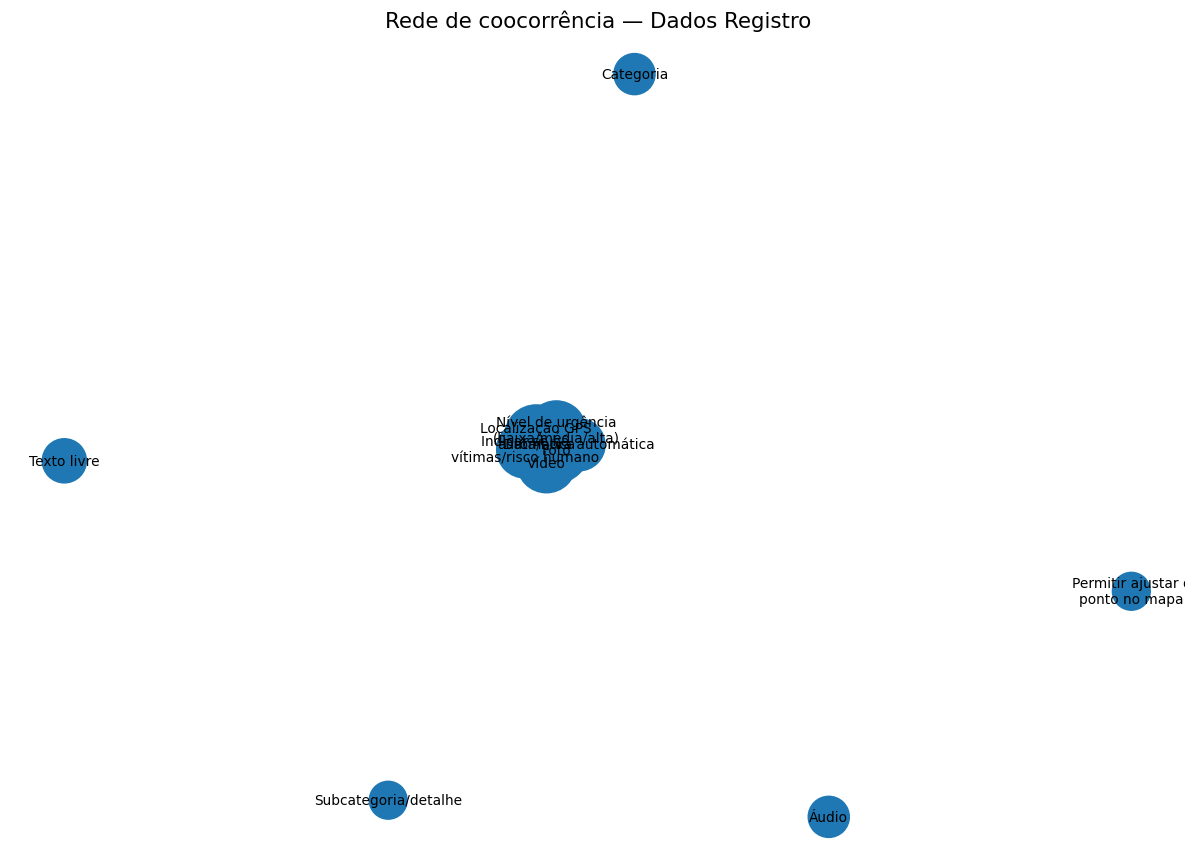

In [16]:
def rede_coocorrencia(df, prefixo, minimo_coocorrencia=3, nome="rede"):
    cooc = matriz_coocorrencia(df, prefixo)
    frequencias = np.diag(cooc.to_numpy())

    G = nx.Graph()

    for i, opcao in enumerate(cooc.index):
        G.add_node(
            opcao,
            frequencia=int(frequencias[i])
        )

    for i in range(len(cooc)):
        for j in range(i + 1, len(cooc)):
            peso = int(cooc.iloc[i, j])

            if peso >= minimo_coocorrencia:
                G.add_edge(
                    cooc.index[i],
                    cooc.columns[j],
                    weight=peso
                )

    if G.number_of_edges() == 0:
        print("Nenhuma aresta atingiu o limiar informado.")
        return G

    pos = nx.spring_layout(G, seed=42)

    node_sizes = [
        500 + G.nodes[n]["frequencia"] * 110
        for n in G.nodes
    ]

    edge_widths = [
        0.7 + G[u][v]["weight"] * 0.5
        for u, v in G.edges
    ]

    labels = {
        n: quebrar_rotulo(n, 20)
        for n in G.nodes
    }

    fig, ax = plt.subplots(figsize=(11, 8))

    nx.draw_networkx_nodes(
        G,
        pos,
        node_size=node_sizes,
        ax=ax
    )
    nx.draw_networkx_edges(
        G,
        pos,
        width=edge_widths,
        alpha=0.55,
        ax=ax
    )
    nx.draw_networkx_labels(
        G,
        pos,
        labels=labels,
        font_size=9,
        ax=ax
    )

    ax.set_title(
        f"Rede de coocorrência — {prefixo.replace('_', ' ').title()}"
    )
    ax.axis("off")

    finalizar_figura(nome)
    return G


G_registro = rede_coocorrencia(
    dados,
    "dados_registro",
    minimo_coocorrencia=4,
    nome="rede_dados_registro"
)

# Parte F — Comparação entre pequenos grupos

Boxplots isolados seriam frágeis em grupos tão pequenos. A figura abaixo combina **boxplot + pontos individuais**, deixando explícitos os 13 casos.

## 16. Utilidade percebida por esfera de atuação

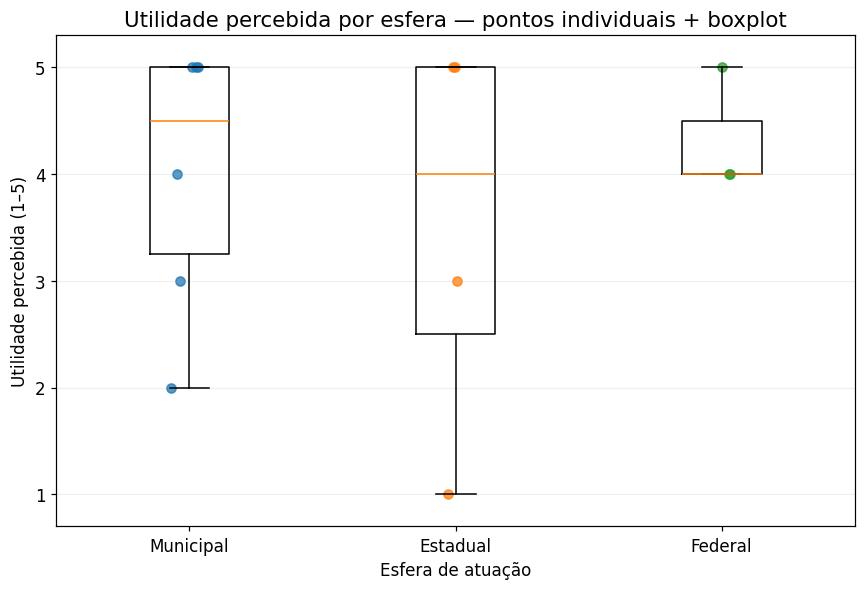

           count  median  mean
nivel                         
Estadual       4     4.0  3.50
Federal        3     4.0  4.33
Municipal      6     4.5  4.00


In [17]:
niveis = [
    n for n in ["Municipal", "Estadual", "Federal"]
    if n in dados["nivel"].dropna().unique()
]

grupos = [
    dados.loc[dados["nivel"] == nivel, "grau_util"].dropna().to_numpy()
    for nivel in niveis
]

fig, ax = plt.subplots(figsize=(8, 5.5))

ax.boxplot(
    grupos,
    tick_labels=niveis,
    showmeans=False
)

rng = np.random.default_rng(42)

for posicao, valores in enumerate(grupos, start=1):
    jitter = rng.normal(0, 0.035, size=len(valores))
    ax.scatter(
        np.full(len(valores), posicao) + jitter,
        valores,
        alpha=0.75
    )

ax.set_ylim(0.7, 5.3)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_ylabel("Utilidade percebida (1–5)")
ax.set_xlabel("Esfera de atuação")
ax.set_title("Utilidade percebida por esfera — pontos individuais + boxplot")
ax.grid(axis="y", alpha=0.2)

finalizar_figura("utilidade_por_nivel_box_jitter")

print(
    dados.groupby("nivel")["grau_util"]
    .agg(["count", "median", "mean"])
    .round(2)
)

## 17. Matriz categórica: esfera de atuação × preferência de explicação

explicacao,Duas versões (técnica + simples),Simples (para gestores),Técnica (para analistas)
nivel,,,
Estadual,25.0,50.0,25.0
Federal,0.0,100.0,0.0
Municipal,66.7,16.7,16.7


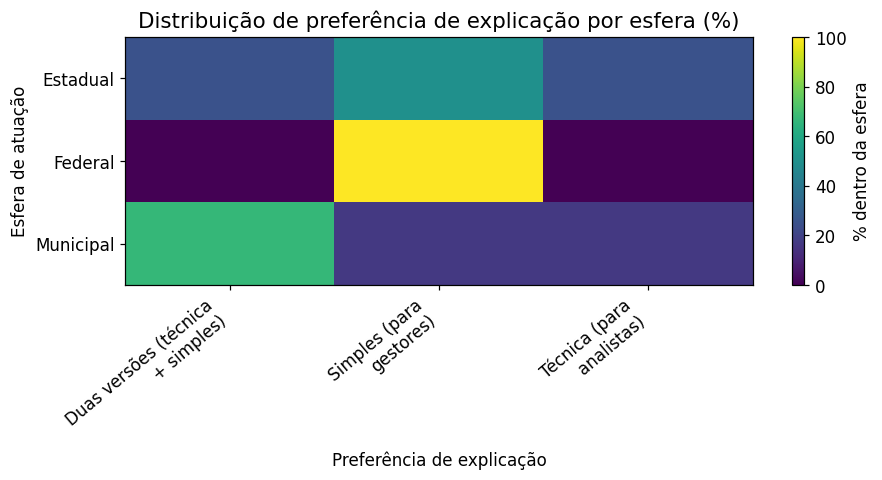

In [18]:
tabela_nivel_explicacao = pd.crosstab(
    dados["nivel"],
    dados["explicacao"],
    normalize="index"
) * 100

display(tabela_nivel_explicacao.round(1))

fig, ax = plt.subplots(
    figsize=(8.5, max(4.5, 0.7 * len(tabela_nivel_explicacao)))
)

im = ax.imshow(
    tabela_nivel_explicacao.to_numpy(),
    aspect="auto",
    vmin=0,
    vmax=100
)

ax.set_xticks(range(len(tabela_nivel_explicacao.columns)))
ax.set_xticklabels(
    [quebrar_rotulo(c, 22) for c in tabela_nivel_explicacao.columns],
    rotation=40,
    ha="right"
)
ax.set_yticks(range(len(tabela_nivel_explicacao.index)))
ax.set_yticklabels(tabela_nivel_explicacao.index)
ax.set_xlabel("Preferência de explicação")
ax.set_ylabel("Esfera de atuação")
ax.set_title("Distribuição de preferência de explicação por esfera (%)")
plt.colorbar(im, ax=ax, label="% dentro da esfera")

finalizar_figura("matriz_nivel_explicacao")

# Parte G — Respostas abertas


## 18. Leitura das respostas abertas

In [19]:
respostas_abertas = dados[
    ["funcionalidades", "riscos"]
].copy()

display(respostas_abertas)

respostas_abertas.to_csv(
    "respostas_abertas_para_codificacao.csv",
    index=False,
    encoding="utf-8-sig"
)

,funcionalidades,riscos
0,"Segurança, transparência e estudos técnicos","Erro, informações incorretas e nervosismo"
1,"Informação precisa, imagem visual da ocorrência, prazo previsto","Informação errada, falta de conhecimento técnico, escassez de recursos para solução do problema"
2,Prevenção de risco,Pânico
3,"Confiança, Eficiência e Design","Erro, desinformação, layout não amigável"
4,"Facilidade de uso, rapidez e desempenho.","Erro, spam e vazamento de dados."
5,"Modelo, mapa, informações confiáveis","Pânico, magnitude, demora na resposta"
6,"Registro de dados, imagens e equipe",Pânico
7,"Comunicação, logística e recursos humanos.","Falta de equipamento, desconhecimento da ocorrência e falha humana."
8,Identificação do risco de desastre com atencendecia de no mínimo 3 horas antes.,A população precisa receber o alerta de forma que não ocasione medo e nem pânico
9,Acessibilidade,Falta de acesso


## 19. Visão lexical exploratória

,frequencia
risco,2
segurança,1
estudos,1
transparência,1
informação,1
precisa,1
imagem,1
visual,1
ocorrência,1
prazo,1


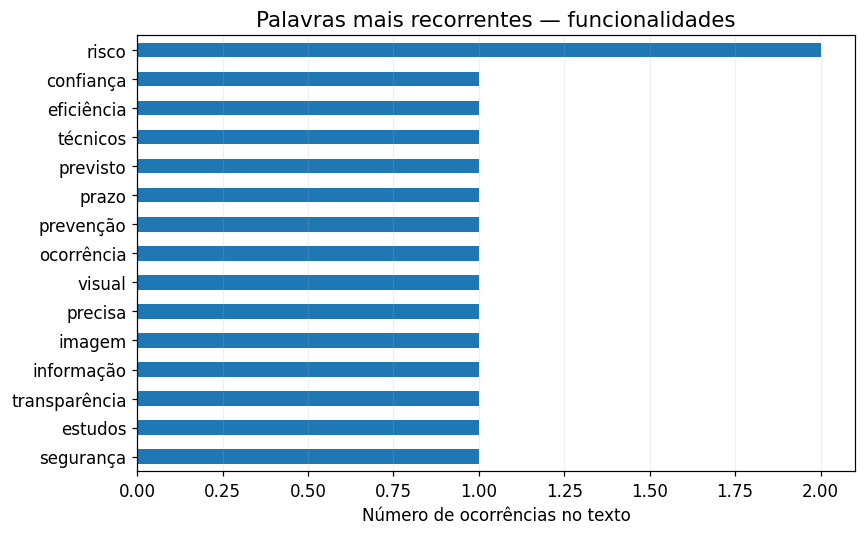

,frequencia
erro,4
pânico,4
falta,3
spam,3
informações,1
informação,1
nervosismo,1
incorretas,1
errada,1
escassez,1


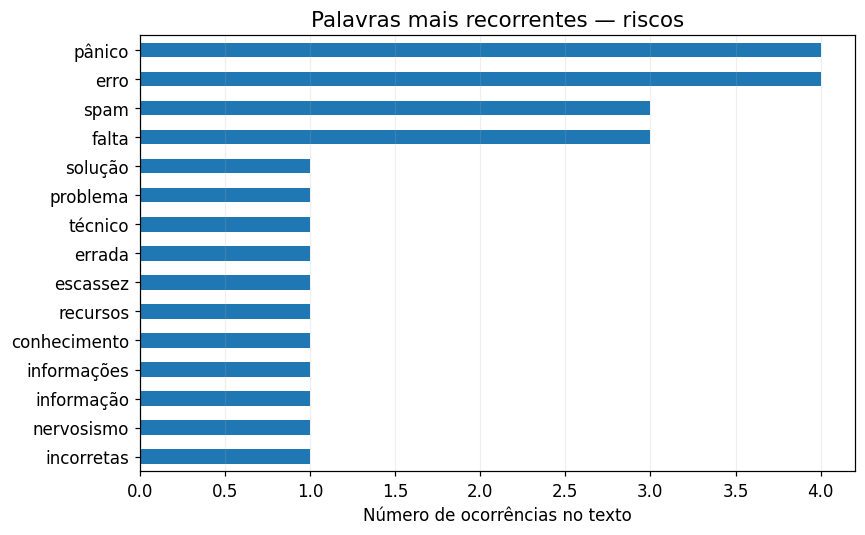

ATENÇÃO: frequência lexical não equivale a tema qualitativo. 


In [21]:
STOPWORDS = {
    "a", "o", "as", "os", "e", "de", "da", "do", "das", "dos",
    "em", "um", "uma", "para", "por", "com", "que", "não", "na",
    "no", "nas", "nos", "se", "ser", "ao", "à", "ou", "mais",
    "como", "forma", "ter", "sem", "sua", "seu"
}


def frequencia_lexical(series, minimo=3):
    texto = " ".join(series.dropna().astype(str)).lower()

    tokens = re.findall(
        r"[a-záàâãéêíóôõúç]{3,}",
        texto
    )

    tokens = [
        t for t in tokens
        if t not in STOPWORDS
    ]

    freq = pd.Series(tokens).value_counts()
    return freq.head(15)


for coluna in ["funcionalidades", "riscos"]:
    freq = frequencia_lexical(dados[coluna])
    display(freq.to_frame("frequencia"))

    fig, ax = plt.subplots(figsize=(8, 5))
    freq.sort_values().plot(kind="barh", ax=ax)
    ax.set_title(
        f"Palavras mais recorrentes — {coluna}"
    )
    ax.set_xlabel("Número de ocorrências no texto")
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.2)

    finalizar_figura(f"lexico_{coluna}")

print(
    "ATENÇÃO: frequência lexical não equivale a tema qualitativo. "
)

# Parte H — Similaridade entre respondentes (experimental)

Este é o ponto mais próximo de uma análise não supervisionada. Usamos distância de Jaccard sobre respostas binárias e agrupamento hierárquico apenas para visualizar quais participantes possuem conjuntos de preferências semelhantes.


## 20. Dendrograma exploratório de similaridade

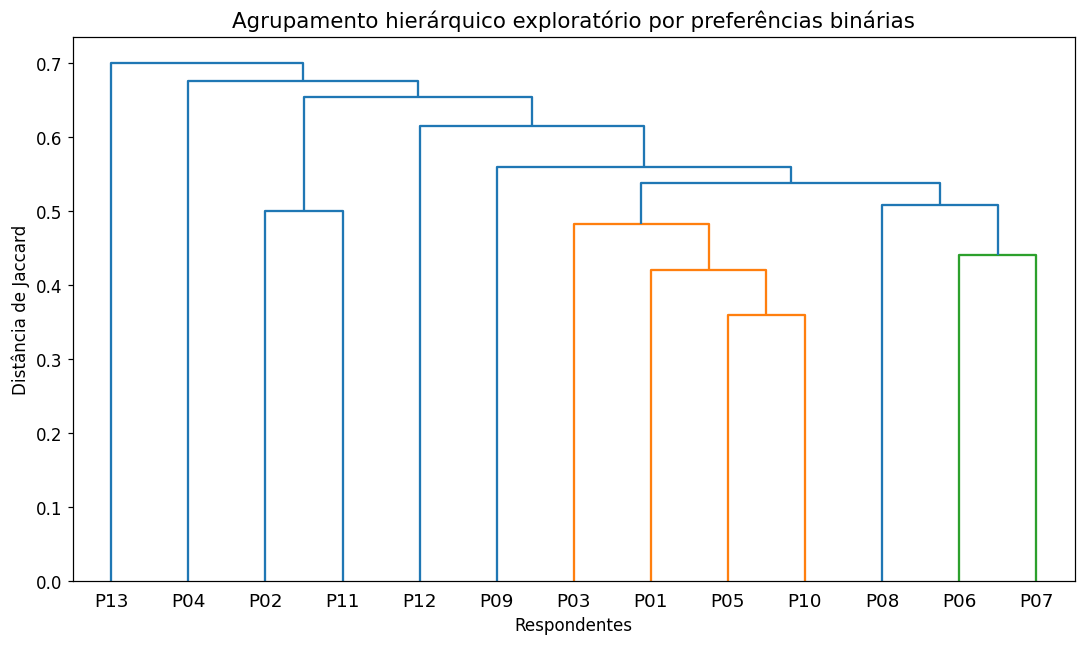

Não interprete os ramos como segmentos estáveis. Com n=13, pequenas mudanças na amostra podem alterar a estrutura.


In [23]:
prefixos_cluster = [
    "dados_registro",
    "telas",
    "filtros_mapa",
    "horizonte_prev",
    "usabilidade",
    "verificacao",
]

cols_cluster = []
for prefixo in prefixos_cluster:
    cols_cluster.extend(indicadores(dados, prefixo))

X_cluster = (
    dados[cols_cluster]
    .fillna(0)
    .astype(bool)
    .to_numpy()
)

distancias = pdist(
    X_cluster,
    metric="jaccard"
)

if np.isnan(distancias).any():
    raise ValueError(
        "A distância de Jaccard produziu NaN. "
        "Revise a matriz binária usada no agrupamento."
    )

Z = linkage(
    distancias,
    method="average"
)

fig, ax = plt.subplots(figsize=(10, 6))

dendrogram(
    Z,
    labels=[f"P{i+1:02d}" for i in range(len(dados))],
    leaf_rotation=0,
    ax=ax
)

ax.set_title(
    "Agrupamento hierárquico exploratório por preferências binárias"
)
ax.set_xlabel("Respondentes")
ax.set_ylabel("Distância de Jaccard")

finalizar_figura("dendrograma_exploratorio_jaccard")

print(
    "Não interprete os ramos como segmentos estáveis. "
    "Com n=13, pequenas mudanças na amostra podem alterar a estrutura."
)